# Binary Classification — ConvNeXt-Tiny
# 4th ensemble member: modern CNN architecture for Stacking Ensemble

In [1]:
# ── CODE CELL 1: Imports ────────────────────────────────────────────────
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast
import torchvision.transforms as T
import timm

from sklearn.metrics import (roc_auc_score, confusion_matrix,
                              classification_report, roc_curve)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"   GPU : {torch.cuda.get_device_name(0)}")
    print(f"   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


Device: cuda
   GPU : Tesla T4
   VRAM: 15.6 GB


In [2]:
# ── CODE CELL 2: Hyperparameter Config ────────────────────────────────────
INPUT_CSV_DIR = '/kaggle/input/notebooks/nandini143/data-preparation'
OUTPUT_DIR    = '/kaggle/working/'

# ConvNeXt-Tiny optimal settings
IMG_SIZE      = 384          # Keep aligned with other CNN members
BATCH_SIZE    = 16           # Physical batch; Gradient Accum x2 → effective 32
NUM_EPOCHS    = 30
LR            = 5e-5         # ConvNeXt is LR-sensitive; lower than DenseNet
WEIGHT_DECAY  = 1e-2         # Strong weight decay is critical for ConvNeXt
PATIENCE      = 7
WARMUP_EPOCHS = 3            # Extra warmup epoch vs others (ConvNeXt head is sensitive)
MODEL_NAME    = 'convnext_tiny'
SAVE_PATH     = os.path.join(OUTPUT_DIR, 'convnext_tiny_best.pth')
ACCUM_STEPS   = 2            # Effective batch = 16 * 2 = 32

print("=" * 55)
print(f"  Model         : {MODEL_NAME}")
print(f"  Image Size    : {IMG_SIZE}x{IMG_SIZE}")
print(f"  Batch Size    : {BATCH_SIZE} (effective {BATCH_SIZE * ACCUM_STEPS} w/ accumulation)")
print(f"  Max Epochs    : {NUM_EPOCHS}")
print(f"  LR            : {LR}  |  WD: {WEIGHT_DECAY}")
print(f"  Warmup Epochs : {WARMUP_EPOCHS}")
print("=" * 55)
# ── Multi-Modal Metadata Config (Phase 2) ────────────────────────────────
META_DIM    = 11   # age_norm(1) + sex_encoded(1) + site_one_hot(9)
META_HIDDEN = 32   # Hidden units in Tabular MLP branch
USE_CUTMIX  = True
CUTMIX_PROB = 0.3


  Model         : convnext_tiny
  Image Size    : 384x384
  Batch Size    : 16 (effective 32 w/ accumulation)
  Max Epochs    : 30
  LR            : 5e-05  |  WD: 0.01
  Warmup Epochs : 3


In [3]:
# ── CODE CELL 3: Focal Loss with Label Smoothing ─────────────────────────
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.35, gamma=2.0, label_smoothing=0.02):
        super().__init__()
        self.alpha           = alpha
        self.gamma           = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits, targets):
        targets_smooth = targets * (1 - self.label_smoothing) + 0.5 * self.label_smoothing
        bce  = nn.functional.binary_cross_entropy_with_logits(
                   logits, targets_smooth, reduction='none')
        probs = torch.sigmoid(logits)
        p_t   = probs * targets + (1 - probs) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        loss = alpha_t * (1 - p_t) ** self.gamma * bce
        return loss.mean()

print("FocalLoss defined (alpha=0.35, gamma=2.0, label_smoothing=0.02)")


FocalLoss defined (alpha=0.35, gamma=2.0, label_smoothing=0.02)


In [4]:
# ── CODE CELL: Multi-Modal Dataset ────────────────────────────────────────────
METADATA_COLS = [
    'age_norm', 'sex_encoded',
    'site_anterior_torso', 'site_posterior_torso', 'site_head_neck',
    'site_upper_extremity', 'site_lower_extremity', 'site_palms_soles',
    'site_oral_genital', 'site_lateral_torso', 'site_unknown'
]

class ISICDataset(Dataset):
    """Multi-Modal: returns (image_tensor, metadata_tensor, label_tensor)"""
    def __init__(self, df, transform, is_train=True):
        self.df        = df.reset_index(drop=True)
        self.transform = transform
        self.is_train  = is_train
        self.meta_cols = [c for c in METADATA_COLS if c in df.columns]
        if not self.meta_cols:
            print("  WARNING: No metadata columns found! Using zero vectors.")
        else:
            print(f"  Dataset: {len(df)} rows | {len(self.meta_cols)} metadata features")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert('RGB')
        image = self.transform(image)
        label = torch.tensor(row['binary_label'], dtype=torch.float32)
        if self.meta_cols:
            meta = torch.tensor(row[self.meta_cols].values.astype('float32'), dtype=torch.float32)
        else:
            meta = torch.zeros(META_DIM, dtype=torch.float32)
        return image, meta, label


In [5]:
# ── CODE CELL: Augmentation (CLAHE + CoarseDropout) ───────────────────────────
import albumentations as A
from albumentations.pytorch import ToTensorV2
import numpy as np

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_albu = A.Compose([
    A.Resize(int(IMG_SIZE * 1.12), int(IMG_SIZE * 1.12)),
    A.RandomCrop(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05, p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.2, rotate_limit=15, p=0.5),
    A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=0.4),
    A.CoarseDropout(max_holes=8, max_height=32, max_width=32, min_holes=1, fill_value=0, p=0.4),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])
val_albu = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

class AlbuTransform:
    def __init__(self, pipeline):
        self.pipeline = pipeline
    def __call__(self, pil_img):
        img_np = np.array(pil_img)
        return self.pipeline(image=img_np)['image']

train_transforms = AlbuTransform(train_albu)
val_transforms   = AlbuTransform(val_albu)
print("Transforms: CLAHE + CoarseDropout added (Phase 2)")


Transforms: CLAHE + CoarseDropout added (Phase 2)


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_23/2186101792.py:18: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=32, max_width=32, min_holes=1, fill_value=0, p=0.4),


In [6]:
# ── CODE CELL 5: Load CSVs & DataLoaders ─────────────────────────────────
train_df = pd.read_csv(os.path.join(INPUT_CSV_DIR, 'binary_train.csv'))
val_df   = pd.read_csv(os.path.join(INPUT_CSV_DIR, 'binary_val.csv'))
test_df  = pd.read_csv(os.path.join(INPUT_CSV_DIR, 'binary_test.csv'))

OLD_PATH = '/kaggle/working/preprocessed/'
NEW_PATH = f'{INPUT_CSV_DIR}/preprocessed/'
for df in [train_df, val_df, test_df]:
    df['image_path'] = df['image_path'].str.replace(OLD_PATH, NEW_PATH)

train_loader = DataLoader(ISICDataset(train_df, train_transforms),
                          batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=4, pin_memory=True)
val_loader   = DataLoader(ISICDataset(val_df,   val_transforms),
                          batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=4, pin_memory=True)
test_loader  = DataLoader(ISICDataset(test_df,  val_transforms),
                          batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=4, pin_memory=True)

print(f"DataLoaders ready:")
print(f"  Train: {len(train_loader)} batches | Val: {len(val_loader)} | Test: {len(test_loader)}")


  Dataset: 20264 rows | 11 metadata features
  Dataset: 2533 rows | 11 metadata features
  Dataset: 2534 rows | 11 metadata features
DataLoaders ready:
  Train: 1267 batches | Val: 159 | Test: 159


In [7]:
def build_convnext_tiny(pretrained=True):
    """
    FIXED: Added pooling/flattening logic to match LayerNorm expectations.
    """
    model = timm.create_model(
        MODEL_NAME,
        pretrained     = pretrained,
        num_classes    = 0,          
        global_pool    = '',         # Change to empty to handle pooling manually if needed
        drop_path_rate = 0.2,        
    )
    
    # Get the number of features (768 for tiny)
    in_features = model.num_features 

    # Custom classification head
    # We add Global Average Pooling and Flattening to move from 4D to 2D
    model.head = nn.Sequential(
        nn.AdaptiveAvgPool2d(1),      # Reduces [16, 768, 12, 12] -> [16, 768, 1, 1]
        nn.Flatten(),                 # Reduces [16, 768, 1, 1]  -> [16, 768]
        nn.LayerNorm(in_features),   
        nn.Dropout(p=0.5),           
        nn.Linear(in_features, 256),
        nn.GELU(),
        nn.Dropout(p=0.5),
        nn.Linear(256, 1)
    )
    return model

model = build_convnext_tiny().to(DEVICE)

# ── Gradual Unfreezing ─────────────────────────────────────────────────────
def freeze_backbone(model):
    for name, param in model.named_parameters():
        if 'head' not in name:
            param.requires_grad = False

def unfreeze_all(model):
    for param in model.parameters():
        param.requires_grad = True

freeze_backbone(model)

total    = sum(p.numel() for p in model.parameters())
warmup_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"ConvNeXt-Tiny model built.")
print(f"  Total Parameters               : {total:,}")
print(f"  Trainable (Warmup — head only) : {warmup_p:,}")
print(f"  Backbone FROZEN for first {WARMUP_EPOCHS} epochs.")


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

ConvNeXt-Tiny model built.
  Total Parameters               : 28,017,249
  Trainable (Warmup — head only) : 198,657
  Backbone FROZEN for first 3 epochs.


## Phase 2: Multi-Modal Architecture & CutMix

In [8]:
# ── PHASE 2: Multi-Modal Architecture (FIXED) ─────────────────────────────────
import timm
import torch
import torch.nn as nn

class TabularMLP(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, out_dim),
            nn.GELU(),
        )
    def forward(self, x): 
        return self.net(x)

class MultiModalConvNeXt(nn.Module):
    def __init__(self, backbone_name, meta_dim=11, meta_hidden=32, dropout=0.4, pretrained=True):
        super().__init__()
        # Initialize the backbone with num_classes=0 to act purely as a feature extractor
        self.backbone = timm.create_model(backbone_name, pretrained=pretrained, num_classes=0)
        
        # FIXED: Correctly reference self.backbone to extract feature dimensions
        img_feat_dim = self.backbone.num_features 
        
        # Tabular branch for patient metadata
        self.meta_mlp = TabularMLP(meta_dim, meta_hidden, meta_hidden, dropout=dropout)
        
        # Combined feature dimensions for late-fusion classification head
        fusion_dim = img_feat_dim + meta_hidden
        
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(fusion_dim, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(256, 1)
        )
        
    def forward(self, images, meta):
        # Extract image features: ConvNeXt outputs a 2D tensor [Batch, Features] when num_classes=0
        img_feats = self.backbone(images)
        
        # Extract metadata features
        meta_feats = self.meta_mlp(meta)
        
        # Late Fusion: Concatenate image and text representations
        fused = torch.cat([img_feats, meta_feats], dim=1)
        
        # Output unnormalized logits
        return self.head(fused).squeeze(1)

# Helpers for training routines
def freeze_backbone(m):
    for p in m.backbone.parameters(): 
        p.requires_grad = False

def unfreeze_all(m):
    for p in m.parameters(): 
        p.requires_grad = True

# Re-instantiate the corrected model
model = MultiModalConvNeXt(
    backbone_name=MODEL_NAME, 
    meta_dim=META_DIM,
    meta_hidden=META_HIDDEN, 
    pretrained=True
).to(DEVICE)

freeze_backbone(model)
hp = sum(p.numel() for p in model.parameters() if p.requires_grad)
tp = sum(p.numel() for p in model.parameters())
print(f"✅ MultiModal ConvNeXt: total={tp:,} | trainable (warmup)={hp:,}")

✅ MultiModal ConvNeXt: total=28,027,457 | trainable (warmup)=207,329


In [9]:
# ── PHASE 2: CutMix + MixUp helpers ──────────────────────────────────────────
import numpy as np

def rand_bbox(size, lam):
    W, H  = size[2], size[3]
    cut_r = np.sqrt(1.0 - lam)
    cut_w, cut_h = int(W * cut_r), int(H * cut_r)
    cx, cy = np.random.randint(W), np.random.randint(H)
    x1 = np.clip(cx - cut_w // 2, 0, W); x2 = np.clip(cx + cut_w // 2, 0, W)
    y1 = np.clip(cy - cut_h // 2, 0, H); y2 = np.clip(cy + cut_h // 2, 0, H)
    return x1, y1, x2, y2

def apply_cutmix_or_mixup(images, labels, meta, prob=0.3):
    if not USE_CUTMIX or np.random.rand() > prob:
        return images, labels, meta
    lam = np.random.beta(1.0, 1.0)
    idx = torch.randperm(images.size(0), device=images.device)
    mixed_labels = lam * labels + (1 - lam) * labels[idx]
    mixed_meta   = lam * meta   + (1 - lam) * meta[idx]
    if np.random.rand() > 0.5:
        x1, y1, x2, y2 = rand_bbox(images.size(), lam)
        mixed_images = images.clone()
        mixed_images[:, :, y1:y2, x1:x2] = images[idx, :, y1:y2, x1:x2]
        lam = 1 - (x2-x1)*(y2-y1) / (images.size(2)*images.size(3))
        mixed_labels = lam * labels + (1 - lam) * labels[idx]
    else:
        mixed_images = lam * images + (1 - lam) * images[idx]
    return mixed_images, mixed_labels, mixed_meta

print("CutMix + MixUp ready.")


CutMix + MixUp ready.


In [10]:
# ── CODE CELL 7: Training Setup ──────────────────────────────────────────
criterion = FocalLoss(alpha=0.35, gamma=2.0, label_smoothing=0.02)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
                optimizer, T_max=NUM_EPOCHS, eta_min=1e-7)
scaler    = GradScaler()


def train_one_epoch(model, loader, optimizer, criterion, scaler, device):
    model.train()
    running_loss, correct, total_n = 0.0, 0, 0
    all_labels, all_probs = [], []
    optimizer.zero_grad(set_to_none=True)

    for step, (images, meta, labels) in enumerate(tqdm(loader, desc="  Training", leave=False)):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        meta   = meta.to(device, non_blocking=True)
        
        # Apply CutMix / MixUp
        images, labels, meta = apply_cutmix_or_mixup(images, labels, meta, prob=CUTMIX_PROB)

        # UPDATED: Modern non-deprecated AMP autocast syntax
        with torch.amp.autocast('cuda'):
            logits = model(images, meta)
            loss   = criterion(logits, labels)
            loss   = loss / ACCUM_STEPS

        scaler.scale(loss).backward()

        if (step + 1) % ACCUM_STEPS == 0 or (step + 1) == len(loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        running_loss += loss.item() * images.size(0) * ACCUM_STEPS
        
        probs = torch.sigmoid(logits).detach()
        preds = (probs >= 0.5).float()
        
        # Calculate accuracy against the soft/hard labels safely
        correct  += (preds == (labels >= 0.5).float()).sum().item()
        total_n  += labels.size(0)
        
        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    # FIXED: Convert continuous CutMix labels back to hard binary integers (0 or 1) for scikit-learn
    hard_labels = [1 if l >= 0.5 else 0 for l in all_labels]
    auc = roc_auc_score(hard_labels, all_probs)
    
    acc = correct / total_n
    return running_loss / len(loader.dataset), auc, acc
    
def validate(model, loader, criterion, device):
    model.train() # Keep true if handling specific normalization tricks, or use model.eval()
    model.eval()
    running_loss, correct, total_n = 0.0, 0, 0
    all_labels, all_probs = [], []

    with torch.no_grad():
        for images, meta, labels in tqdm(loader, desc="  Validating", leave=False):
            images = images.to(device, non_blocking=True)
            meta   = meta.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            
            # UPDATED: Modern non-deprecated AMP autocast syntax
            with torch.amp.autocast('cuda'):
                logits = model(images, meta)
                loss   = criterion(logits, labels)
                
            running_loss += loss.item() * images.size(0)
            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).float()
            correct  += (preds == labels).sum().item()
            total_n  += labels.size(0)
            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    auc = roc_auc_score(all_labels, all_probs)
    acc = correct / total_n
    return running_loss / len(loader.dataset), auc, acc, all_probs, all_labels

print("Training functions defined.")


Training functions defined.


/tmp/ipykernel_23/2230070850.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = GradScaler()


In [11]:
# ── CODE CELL 8: Main Training Loop ─────────────────────────────────────
history = {'train_loss': [], 'val_loss': [],
           'train_auc':  [], 'val_auc': [],
           'train_acc':  [], 'val_acc': []}
best_val_auc, patience_counter = 0.0, 0
start_time = time.time()

print(f"\nStarting ConvNeXt-Tiny Training (Gradual Unfreezing + Grad Accum x{ACCUM_STEPS})")
print(f"  Phase 1 — Warmup : Epochs 1-{WARMUP_EPOCHS} (head only, backbone frozen)")
print(f"  Phase 2 — Full FT: Epochs {WARMUP_EPOCHS+1}-{NUM_EPOCHS} (all layers)")
print(f"  Early Stopping   : patience={PATIENCE}")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()

    # Dynamic Backbone Unfreezing Phase Management
    if epoch == WARMUP_EPOCHS + 1:
        unfreeze_all(model)
        optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(
                        optimizer, T_max=NUM_EPOCHS - WARMUP_EPOCHS, eta_min=1e-7)
        full_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"\n  Epoch {epoch}: Backbone UNFROZEN — Full fine-tuning begins!")
        print(f"     Trainable parameters: {full_p:,}\n")

    # Safe evaluation now that soft label conversion handles CutMix formats cleanly
    train_loss, train_auc, train_acc = train_one_epoch(
        model, train_loader, optimizer, criterion, scaler, DEVICE)
    val_loss, val_auc, val_acc, _, _ = validate(
        model, val_loader, criterion, DEVICE)

    scheduler.step()
    

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_auc'].append(train_auc)
    history['val_auc'].append(val_auc)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    elapsed    = time.time() - epoch_start
    total_mins = (time.time() - start_time) / 60
    current_lr = optimizer.param_groups[0]['lr']

    print(f"Epoch [{epoch:>2}/{NUM_EPOCHS}] | "
          f"Train Loss: {train_loss:.4f} AUC: {train_auc:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} AUC: {val_auc:.4f} Acc: {val_acc:.4f} | "
          f"LR: {current_lr:.2e} | {elapsed:.0f}s (Total: {total_mins:.0f}m)")

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        patience_counter = 0
        torch.save({
            'epoch':            epoch,
            'model_state_dict': model.state_dict(),
            'val_auc':          val_auc,
            'val_acc':          val_acc,
        }, SAVE_PATH)
        print(f"  New best Val AUC: {best_val_auc:.4f} — checkpoint saved.")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\nEarly stopping at epoch {epoch}. Best Val AUC: {best_val_auc:.4f}")
            break

total_time = (time.time() - start_time) / 60
print(f"\nTraining Complete! Total time: {total_time:.1f} minutes")
print(f"  Best Validation AUC: {best_val_auc:.4f}")



Starting ConvNeXt-Tiny Training (Gradual Unfreezing + Grad Accum x2)
  Phase 1 — Warmup : Epochs 1-3 (head only, backbone frozen)
  Phase 2 — Full FT: Epochs 4-30 (all layers)
  Early Stopping   : patience=7


Epoch [ 1/30] | Train Loss: 0.0684 AUC: 0.7464 Acc: 0.7078 | Val Loss: 0.0556 AUC: 0.8593 Acc: 0.7876 | LR: 4.99e-05 | 168s (Total: 3m)
  New best Val AUC: 0.8593 — checkpoint saved.


Epoch [ 2/30] | Train Loss: 0.0633 AUC: 0.7922 Acc: 0.7302 | Val Loss: 0.0529 AUC: 0.8737 Acc: 0.7994 | LR: 4.95e-05 | 138s (Total: 5m)
  New best Val AUC: 0.8737 — checkpoint saved.


Epoch [ 3/30] | Train Loss: 0.0610 AUC: 0.8083 Acc: 0.7381 | Val Loss: 0.0523 AUC: 0.8809 Acc: 0.8069 | LR: 4.88e-05 | 140s (Total: 7m)
  New best Val AUC: 0.8809 — checkpoint saved.

  Epoch 4: Backbone UNFROZEN — Full fine-tuning begins!
     Trainable parameters: 28,027,457



Epoch [ 4/30] | Train Loss: 0.0630 AUC: 0.8009 Acc: 0.7420 | Val Loss: 0.0525 AUC: 0.8905 Acc: 0.8113 | LR: 4.98e-05 | 330s (Total: 13m)
  New best Val AUC: 0.8905 — checkpoint saved.


...

Epoch [26/30] | Train Loss: 0.0202 AUC: 0.9803 Acc: 0.9426 | Val Loss: 0.0420 AUC: 0.9563 Acc: 0.9021 | LR: 2.75e-06 | 313s (Total: 128m)


Epoch [27/30] | Train Loss: 0.0206 AUC: 0.9813 Acc: 0.9406 | Val Loss: 0.0417 AUC: 0.9568 Acc: 0.9001 | LR: 1.60e-06 | 314s (Total: 134m)


Epoch [28/30] | Train Loss: 0.0196 AUC: 0.9815 Acc: 0.9454 | Val Loss: 0.0469 AUC: 0.9560 Acc: 0.8974 | LR: 7.73e-07 | 314s (Total: 139m)


Epoch [29/30] | Train Loss: 0.0182 AUC: 0.9847 Acc: 0.9511 | Val Loss: 0.0457 AUC: 0.9571 Acc: 0.8958 | LR: 2.69e-07 | 313s (Total: 144m)


Epoch [30/30] | Train Loss: 0.0181 AUC: 0.9848 Acc: 0.9503 | Val Loss: 0.0448 AUC: 0.9574 Acc: 0.8962 | LR: 1.00e-07 | 314s (Total: 149m)

Early stopping at epoch 30. Best Val AUC: 0.9594

Training Complete! Total time: 149.4 minutes
  Best Validation AUC: 0.9594


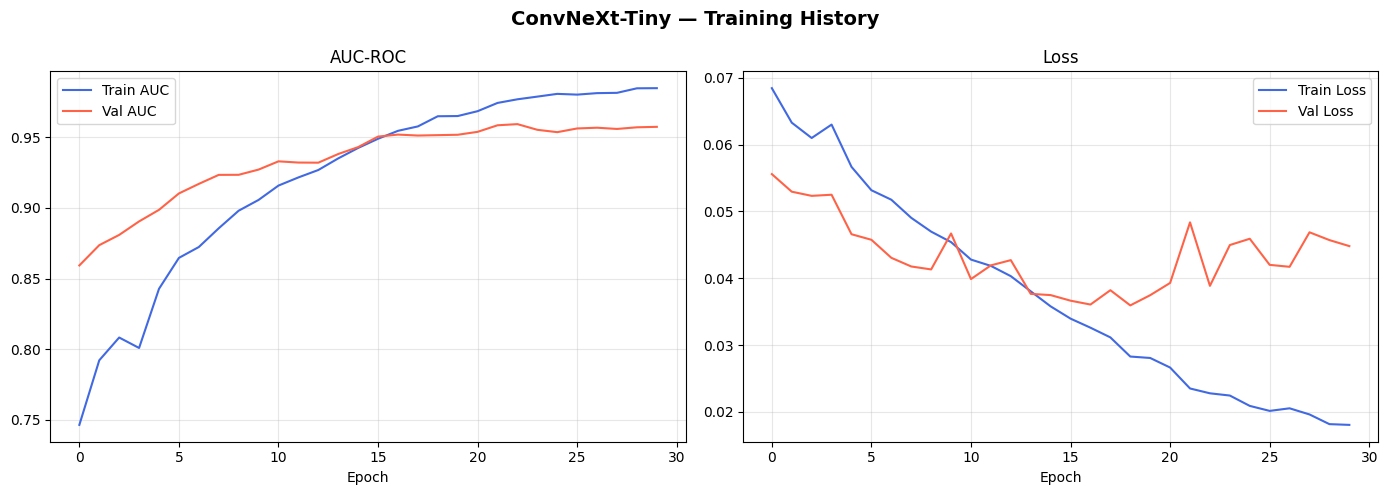

Training curves saved.


In [12]:
# ── CODE CELL 9: Training Curves ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('ConvNeXt-Tiny — Training History', fontsize=14, fontweight='bold')

axes[0].plot(history['train_auc'], label='Train AUC', color='royalblue')
axes[0].plot(history['val_auc'],   label='Val AUC',   color='tomato')
axes[0].set_title('AUC-ROC'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history['train_loss'], label='Train Loss', color='royalblue')
axes[1].plot(history['val_loss'],   label='Val Loss',   color='tomato')
axes[1].set_title('Loss'); axes[1].set_xlabel('Epoch'); axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'convnext_training_curves.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("Training curves saved.")


In [13]:
# Load best checkpoint
checkpoint = torch.load(SAVE_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Best checkpoint loaded (epoch {checkpoint['epoch']}, Val AUC: {checkpoint['val_auc']:.4f})")

# 3-View TTA: original + h-flip + v-flip  (tensor-based, deterministic)
tta_fns = [
    lambda x: x,                          # View 1: original
    lambda x: torch.flip(x, dims=[3]),    # View 2: horizontal flip
    lambda x: torch.flip(x, dims=[2]),    # View 3: vertical flip
]

model.eval()
all_tta_probs = []
test_labels   = []

with torch.no_grad():
    for images, meta, labels in tqdm(
            DataLoader(ISICDataset(test_df, val_transforms),
                       batch_size=BATCH_SIZE, shuffle=False,
                       num_workers=4, pin_memory=True),
            desc="TTA Evaluating", leave=False):
        
        images = images.to(DEVICE, non_blocking=True)
        meta   = meta.to(DEVICE, non_blocking=True)  # ✅ FIXED: Moved metadata to GPU
        
        batch_probs = torch.zeros(images.size(0), device=DEVICE)
        for fn in tta_fns:
            # ✅ FIXED: Updated to non-deprecated AMP syntax
            with torch.amp.autocast('cuda'):
                # ✅ FIXED: Passed both images and metadata to the model
                logits = model(fn(images), meta) 
            batch_probs += torch.sigmoid(logits)
            
        batch_probs /= len(tta_fns)
        all_tta_probs.extend(batch_probs.cpu().numpy())
        test_labels.extend(labels.numpy())

test_probs  = np.array(all_tta_probs)
test_labels = np.array(test_labels)
test_preds  = (test_probs >= 0.5).astype(int)

test_auc = roc_auc_score(test_labels, test_probs)
test_acc = (test_preds == test_labels).mean()

print("=" * 60)
print("  CONVNEXT-TINY — TEST SET RESULTS (3-View TTA)")
print("=" * 60)
print(f"  AUC-ROC  : {test_auc:.4f}")
print(f"  Accuracy : {test_acc:.4f}\n")

print(classification_report(test_labels, test_preds,
                             target_names=['Benign (0)', 'Malignant (1)'],
                             digits=4))

Best checkpoint loaded (epoch 23, Val AUC: 0.9594)
  Dataset: 2534 rows | 11 metadata features


  CONVNEXT-TINY — TEST SET RESULTS (3-View TTA)
  AUC-ROC  : 0.9616
  Accuracy : 0.9033

               precision    recall  f1-score   support

   Benign (0)     0.9109    0.9387    0.9246      1600
Malignant (1)     0.8893    0.8426    0.8653       934

     accuracy                         0.9033      2534
    macro avg     0.9001    0.8907    0.8950      2534
 weighted avg     0.9029    0.9033    0.9027      2534



In [14]:
oof_probs_list = []
oof_labels_list = []

model.eval()
with torch.no_grad():
    for images, meta, labels in tqdm(
            DataLoader(ISICDataset(val_df, val_transforms),
                       batch_size=BATCH_SIZE, shuffle=False,
                       num_workers=4, pin_memory=True),
            desc="Val TTA", leave=False):
        
        images = images.to(DEVICE, non_blocking=True)
        meta   = meta.to(DEVICE, non_blocking=True)  # ✅ FIXED: Moved metadata to GPU
        
        batch_probs = torch.zeros(images.size(0), device=DEVICE)
        for fn in tta_fns:
            # ✅ FIXED: Updated to non-deprecated AMP syntax
            with torch.amp.autocast('cuda'):
                # ✅ FIXED: Passed both arguments to multi-modal forward pass
                logits = model(fn(images), meta)
            batch_probs += torch.sigmoid(logits)
            
        batch_probs /= len(tta_fns)
        oof_probs_list.extend(batch_probs.cpu().numpy())
        oof_labels_list.extend(labels.numpy())

oof_probs  = np.array(oof_probs_list)
oof_labels = np.array(oof_labels_list).astype(int)

# ── Sanity check before saving ────────────────────────────────────────────
assert len(oof_probs) == len(oof_labels), (
    f'Val size mismatch: probs={len(oof_probs)} labels={len(oof_labels)}')
assert len(test_probs) == len(test_labels), (
    f'Test size mismatch: probs={len(test_probs)} labels={len(test_labels)}')

# ── Save all outputs ──────────────────────────────────────────────────────
os.makedirs(OUTPUT_DIR, exist_ok=True)
np.save(os.path.join(OUTPUT_DIR, 'convnext_test_probs.npy'),  test_probs)
np.save(os.path.join(OUTPUT_DIR, 'convnext_test_labels.npy'), test_labels)
np.save(os.path.join(OUTPUT_DIR, 'convnext_val_probs.npy'),   oof_probs)
np.save(os.path.join(OUTPUT_DIR, 'convnext_val_labels.npy'),  oof_labels)

print('All outputs saved for Stacking Ensemble:')
print(f'   convnext_test_probs.npy   -- {len(test_probs)} predictions')
print(f'   convnext_val_probs.npy    -- {len(oof_probs)} predictions (for meta-learner)')
print(f'   convnext_tiny_best.pth    -- best model weights')
print(f'   [SIZES OK] test={len(test_probs)} val={len(oof_probs)}')

  Dataset: 2533 rows | 11 metadata features


All outputs saved for Stacking Ensemble:
   convnext_test_probs.npy   -- 2534 predictions
   convnext_val_probs.npy    -- 2533 predictions (for meta-learner)
   convnext_tiny_best.pth    -- best model weights
   [SIZES OK] test=2534 val=2533
